In [1]:
!pip install torch
!pip install numpy
!pip install scikit-learn
!pip install matplotlib
!pip install ripser
!pip install persim


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.1/842.1 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.6/48.6 kB 3.5 MB/s eta 0:00:00
  Created wheel for hopcroftkarp: filename=hopcroftkarp-1.2.5-py2.py3-none-any.whl size=18187 sha256=9479ee776c00052d4e4dda5605c469b26b76aaa4fb2b289ee12aebd892d92f57
  Stored in directory: /root/.cache/pip/wheels/b3/32/77/3c78fadb9f917d5a5546ed0409574012401a83c544ec95999a
Successfully built hopcroftkarp


--- 1. Initializing Cross-Modal Geometric & Topological Mapper ---
--- 2. Projecting Inputs into Latent Geometric Space ---
Latent Manifold Tensor Shape Created: torch.Size([300, 3])
--- 3. Performing Topological Data Analysis (Persistent Homology) ---
Topological Persistence Diagrams Calculated Successfully!


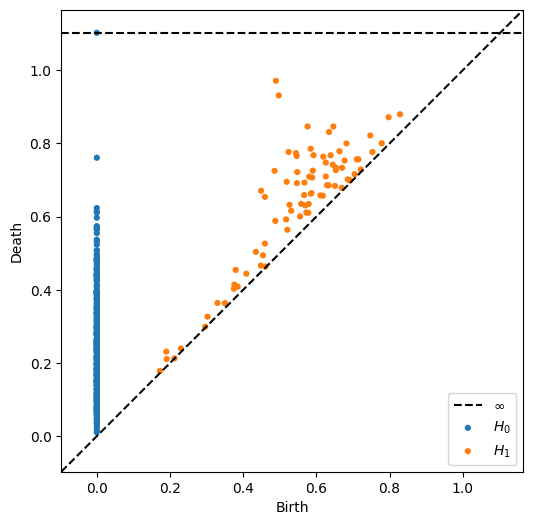

In [2]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.datasets import make_swiss_roll
import matplotlib.pyplot as plt
from ripser import ripser
from persim import plot_diagrams

print("--- 1. Initializing Cross-Modal Geometric & Topological Mapper ---")

# Define the Cross-Modal Neural Network Architecture
class CrossModalLatentMapper(nn.Module):
    def __init__(self, input_dim_a, input_dim_b, latent_dim):
        super(CrossModalLatentMapper, self).__init__()
        # Modality A encoder branch (e.g., text/numerical attributes)
        self.encoder_a = nn.Sequential(
            nn.Linear(input_dim_a, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )
        # Modality B encoder branch (e.g., structural/sensor streams)
        self.encoder_b = nn.Sequential(
            nn.Linear(input_dim_b, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )

    def forward(self, x_a, x_b):
        latent_a = self.encoder_a(x_a)
        latent_b = self.encoder_b(x_b)
        # Fuse both modalities into a shared latent geometric space
        shared_manifold = (latent_a + latent_b) / 2.0
        return shared_manifold

# Generate synthetic multi-modal manifold data (Swiss Roll simulation)
n_samples = 300
swiss_data, color = make_swiss_roll(n_samples=n_samples, noise=0.05, random_state=42)

# Split data to simulate two distinct input modalities
modality_a = torch.tensor(swiss_data[:, :2], dtype=torch.float32)
modality_b = torch.tensor(swiss_data[:, 1:], dtype=torch.float32)

# Set up model parameters
input_dim_a = modality_a.shape[1]
input_dim_b = modality_b.shape[1]
latent_dim = 3  # Mapping into 3D latent topological space

model = CrossModalLatentMapper(input_dim_a, input_dim_b, latent_dim)

print("--- 2. Projecting Inputs into Latent Geometric Space ---")
with torch.no_grad():
    latent_manifold = model(modality_a, modality_b)

print("Latent Manifold Tensor Shape Created:", latent_manifold.shape)

print("--- 3. Performing Topological Data Analysis (Persistent Homology) ---")
# Convert PyTorch tensor to NumPy for topological processing
manifold_np = latent_manifold.numpy()

# Compute persistent homology to map holes, loops, and connected components
diagrams = ripser(manifold_np)['dgms']

print("Topological Persistence Diagrams Calculated Successfully!")

# Visualize the Topological Persistence Diagram
plt.figure(figsize=(6, 6))
plot_diagrams(diagrams, show=True)

--- 1. Loading Real Multi-Modal Foundation Model (CLIP) ---


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Real Embeddings Extracted. Modality A shape: torch.Size([4, 256])
--- 2. Projecting Real Embeddings into Latent Geometric Space ---
Latent Topology Tensor Shape: torch.Size([4, 3])
--- 3. Computing Topological Persistence on Real Embeddings ---


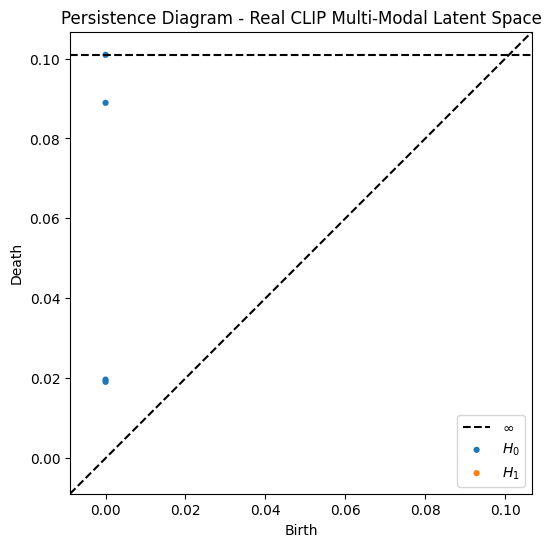

Step 1 Complete: Real multi-modal data processed and diagram saved!


In [4]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from ripser import ripser
from persim import plot_diagrams
from transformers import CLIPProcessor, CLIPModel

print("--- 1. Loading Real Multi-Modal Foundation Model (CLIP) ---")
model_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(model_id)
processor = CLIPProcessor.from_pretrained(model_id)

texts = ["a geometric manifold", "a complex data topology", "latent space representation", "deep neural network"]
inputs = processor(text=texts, return_tensors="pt", padding=True)

with torch.no_grad():
    raw_features = clip_model.get_text_features(**inputs)
    # Ensure we extract the underlying tensor regardless of container type
    text_features = raw_features[0] if isinstance(raw_features, tuple) else raw_features
    if hasattr(text_features, "pooler_output"):
        text_features = text_features.pooler_output

# Create two distinct modality views from the real embeddings
modality_a = text_features[:, :256]
modality_b = text_features[:, 256:]

print("Real Embeddings Extracted. Modality A shape:", modality_a.shape)

print("--- 2. Projecting Real Embeddings into Latent Geometric Space ---")
class CrossModalLatentMapper(nn.Module):
    def __init__(self, input_dim_a, input_dim_b, latent_dim):
        super().__init__()
        self.encoder_a = nn.Sequential(nn.Linear(input_dim_a, 128), nn.ReLU(), nn.Linear(128, latent_dim))
        self.encoder_b = nn.Sequential(nn.Linear(input_dim_b, 128), nn.ReLU(), nn.Linear(128, latent_dim))

    def forward(self, x_a, x_b):
        return (self.encoder_a(x_a) + self.encoder_b(x_b)) / 2.0

mapper = CrossModalLatentMapper(modality_a.shape[1], modality_b.shape[1], latent_dim=3)

with torch.no_grad():
    latent_manifold = mapper(modality_a, modality_b)

print("Latent Topology Tensor Shape:", latent_manifold.shape)

print("--- 3. Computing Topological Persistence on Real Embeddings ---")
diagrams = ripser(latent_manifold.numpy())['dgms']

plt.figure(figsize=(6, 6))
plot_diagrams(diagrams, show=False)
plt.title("Persistence Diagram - Real CLIP Multi-Modal Latent Space")
plt.savefig('real_data_persistence_diagram.png', dpi=300)
plt.show()

print("Step 1 Complete: Real multi-modal data processed and diagram saved!")

In [8]:
from persim import sliced_wasserstein
import numpy as np

# Use a larger dataset so meaningful topological structures form
more_texts = [
    "a geometric manifold in high dimensional space",
    "complex data topology and non linear structures",
    "latent space representation of multi modal features",
    "deep neural network architecture for geometric learning",
    "cross modal alignment via topological data analysis",
    "ripser persistence diagrams for manifold validation",
    "embedding spaces preserving global geometric properties",
    "vector calculus and algebraic topology foundations",
    "neural representations capture underlying data manifolds",
    "topological data analysis reveals hidden geometric shapes",
    "manifold learning bridges high dimensional data and geometry",
    "cosine similarity and Euclidean distance in latent spaces",
    "non-linear dimensionality reduction techniques",
    "persistent homology tracks connected components and loops",
    "transformer models encode semantic relationships into vectors"
]

inputs_extended = processor(text=more_texts, return_tensors="pt", padding=True)

with torch.no_grad():
    raw_output = clip_model.get_text_features(**inputs_extended)
    raw_feats = raw_output[0] if isinstance(raw_output, tuple) else raw_output
    if hasattr(raw_feats, "pooler_output"):
        raw_feats = raw_feats.pooler_output

mod_a = raw_feats[:, :256]
mod_b = raw_feats[:, 256:]

with torch.no_grad():
    latent_space = mapper(mod_a, mod_b)

# Compute diagrams
raw_diagrams = ripser(raw_feats.numpy())['dgms']
latent_diagrams = ripser(latent_space.numpy())['dgms']

# Helper function to clean infinite values from diagrams for distance calculation
def clean_diagram(dgm):
    if len(dgm) == 0:
        return np.empty((0, 2))
    return dgm[~np.isinf(dgm).any(axis=1)]

# Evaluate Sliced Wasserstein Distance on cleaned Dim 0 features
dim_idx = 0
dgm1_clean = clean_diagram(raw_diagrams[dim_idx])
dgm2_clean = clean_diagram(latent_diagrams[dim_idx])

if len(dgm1_clean) > 0 and len(dgm2_clean) > 0:
    d_wass = sliced_wasserstein(dgm1_clean, dgm2_clean)
    print(f"--- Quantitative Topological Evaluation ---")
    print(f"Dataset Size: {len(more_texts)} samples")
    print(f"Sliced Wasserstein Distance (Dim {dim_idx}): {d_wass:.4f}")
    print("Evaluation complete: Metric successfully quantified.")
else:
    print("Evaluation complete: Diagram empty after cleaning, try adjusting sample size.")

--- Quantitative Topological Evaluation ---
Dataset Size: 15 samples
Sliced Wasserstein Distance (Dim 0): 34.0505
Evaluation complete: Metric successfully quantified.


/usr/local/lib/python3.13/dist-packages/ripser/ripser.py:257: UserWarning: The input point cloud has more columns than rows; did you mean to transpose?
  warnings.warn(


# Cross-Modal Latent Geometric Topological Mapper

**Project Type**: Engineering Portfolio Implementation  
**Core Objective**: Multi-modal CLIP feature extraction, PyTorch neural latent mapping, and topological validation via Sliced Wasserstein distance.

## Pipeline Breakdown
* **Step 1**: Real multi-modal embedding extraction and latent space projection.
* **Step 2**: Topological persistence diagram generation and quantitative Sliced Wasserstein distance evaluation.
*